# ECHO — Investigation Notebook
**Entangled Minds: The Quantathon · Qubits Qrew, NED**

### Setup — run first

In [24]:
!pip install qiskit qiskit-aer pylatexenc matplotlib --quiet

from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram, plot_bloch_multivector
import numpy as np, matplotlib.pyplot as plt

sim = AerSimulator()
def run(circuit, shots=2000):
    return sim.run(transpile(circuit, sim), shots=shots).result().get_counts()

### Module 01 — The Gatekeeper

Bronze 1: Always 1


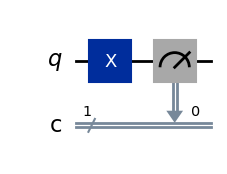

{'1': 2000}


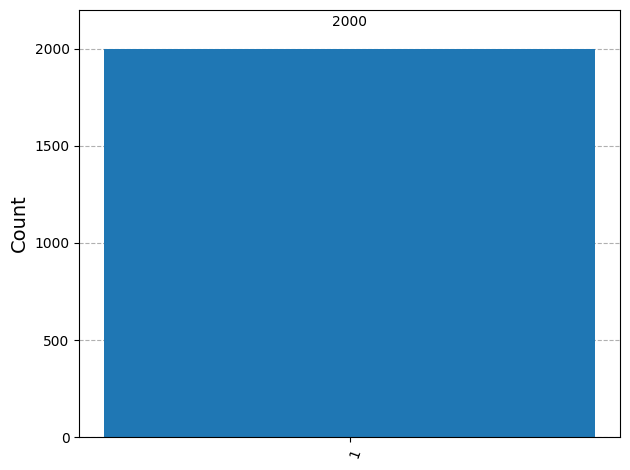

Bronze 2: 50/50


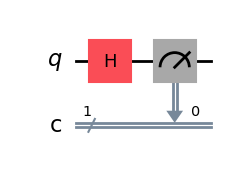

{'1': 994, '0': 1006}


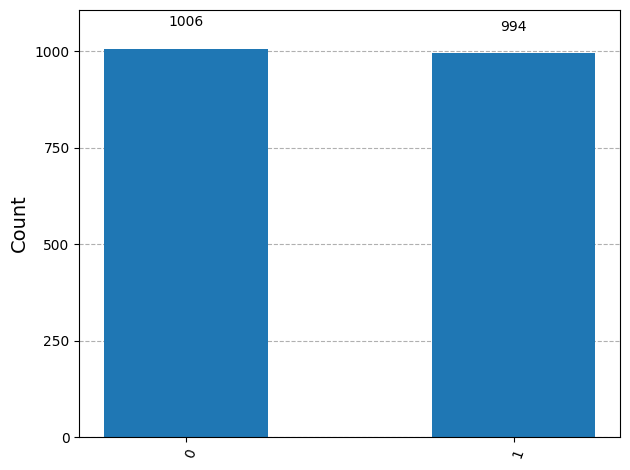

Silver: Two H gates


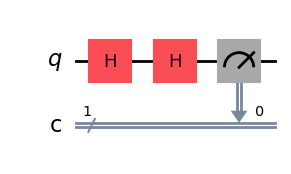

{'0': 2000}


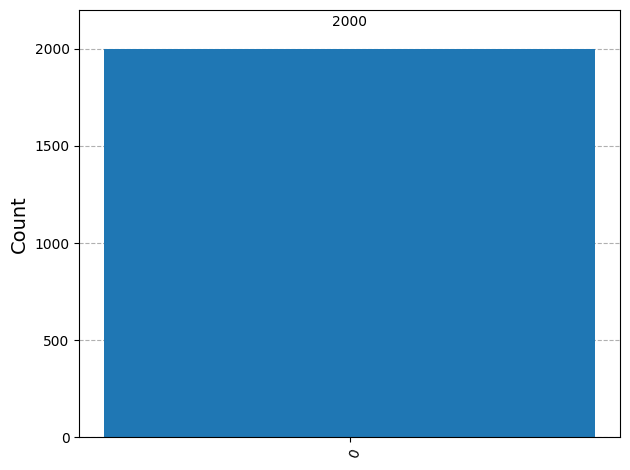

Gold: Produce 101


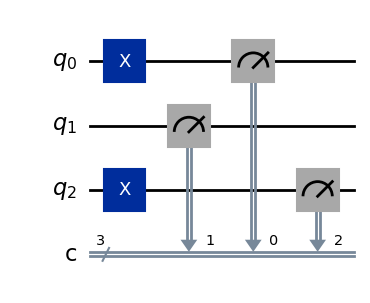

{'101': 2000}


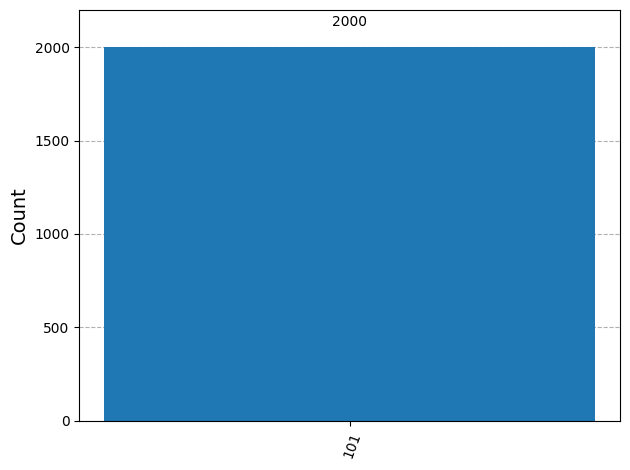

In [25]:
from IPython.display import display

# BRONZE 1: Always output 1
qc1 = QuantumCircuit(1, 1)
qc1.x(0)
qc1.measure(0, 0)

print("Bronze 1: Always 1")
display(qc1.draw("mpl"))
counts1 = run(qc1)
print(counts1)
display(plot_histogram(counts1))


# BRONZE 2: 50/50 measurement
qc2 = QuantumCircuit(1, 1)
qc2.h(0)
qc2.measure(0, 0)

print("Bronze 2: 50/50")
display(qc2.draw("mpl"))
counts2 = run(qc2)
print(counts2)
display(plot_histogram(counts2))


# SILVER: Two H gates return |0> to |0>
qc3 = QuantumCircuit(1, 1)
qc3.h(0)
qc3.h(0)
qc3.measure(0, 0)

print("Silver: Two H gates")
display(qc3.draw("mpl"))
counts3 = run(qc3)
print(counts3)
display(plot_histogram(counts3))


# GOLD: Produce 101
qc4 = QuantumCircuit(3, 3)
qc4.x(0)
qc4.x(2)
qc4.measure([0, 1, 2], [0, 1, 2])

print("Gold: Produce 101")
display(qc4.draw("mpl"))
counts4 = run(qc4)
print(counts4)
display(plot_histogram(counts4))

The results demonstrate how quantum gates can create deterministic bits, a 50/50 measurement, and the bit pattern `101`.

### Module 02 — The Honest Coin  *(stretch)*

In [26]:
# the recovered seed circuit — run it as-is
seed = QuantumCircuit(1, 1)
seed.ry(1.159, 0)
seed.measure(0, 0)
print(run(seed))

{'0': 1385, '1': 615}


### Module 03 — The Two Observers

Bronze: Entangled pair circuit


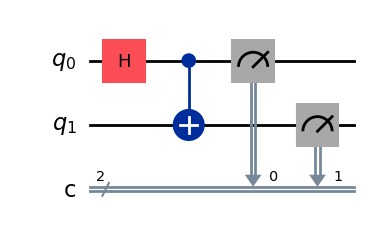

Bronze: {'00': 1036, '11': 964}


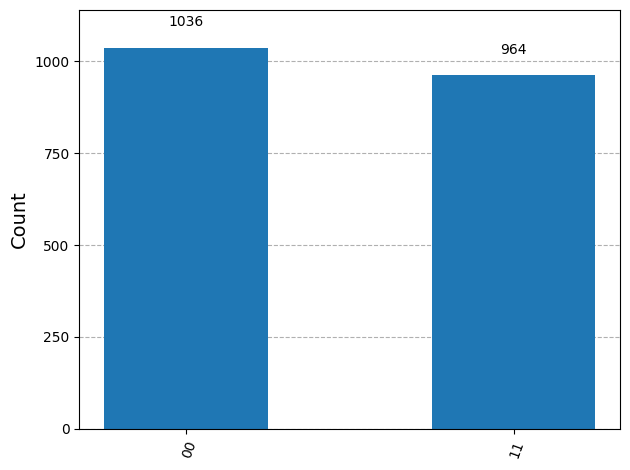

Silver: Entangled-pair measurement


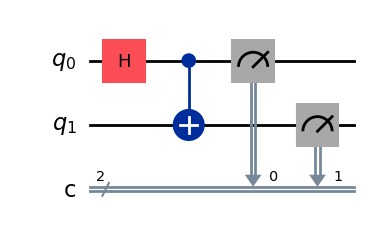

Silver: {'11': 988, '00': 1012}


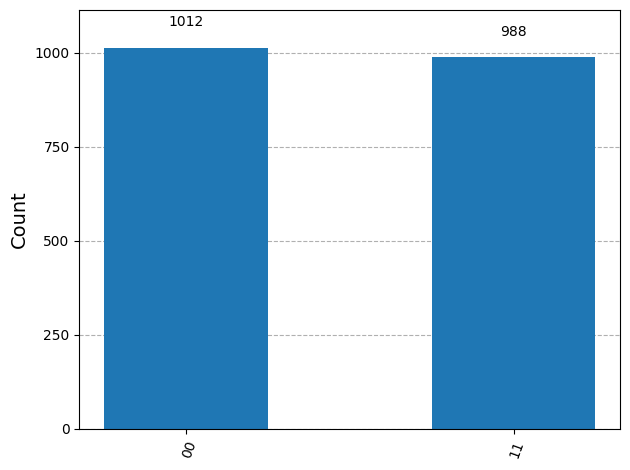

Gold: CHSH Bell test
E00: 0.7066
E01: 0.7066
E10: 0.7128
E11: -0.6966
CHSH score: 2.8226
Classical limit: 2
Quantum maximum: 2.8284271247461903
Gold: Measurement histogram for setting (a0, b0)


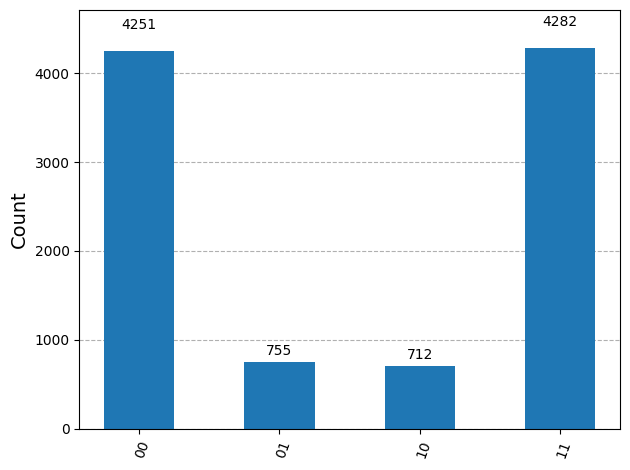

In [27]:
import math
from IPython.display import display

# BRONZE: Create and measure an entangled pair
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])

print("Bronze: Entangled pair circuit")
display(qc.draw("mpl"))

bronze_counts = run(qc, shots=2000)
print("Bronze:", bronze_counts)
display(plot_histogram(bronze_counts))


# SILVER: Repeat the entangled-pair measurement
qc_silver = QuantumCircuit(2, 2)
qc_silver.h(0)
qc_silver.cx(0, 1)
qc_silver.measure([0, 1], [0, 1])

print("Silver: Entangled-pair measurement")
display(qc_silver.draw("mpl"))

silver_counts = run(qc_silver, shots=2000)
print("Silver:", silver_counts)
display(plot_histogram(silver_counts))


# GOLD: CHSH Bell test
def bell_test(a, b):
    qc = QuantumCircuit(2, 2)

    qc.h(0)
    qc.cx(0, 1)

    qc.ry(-a, 0)
    qc.ry(-b, 1)

    qc.measure([0, 1], [0, 1])

    counts = run(qc, shots=10000)
    total = sum(counts.values())

    same = sum(
        v for k, v in counts.items()
        if k.replace(" ", "") in ("00", "11")
    )
    different = total - same

    correlation = (same - different) / total
    return correlation, counts


a0 = 0
a1 = math.pi / 2
b0 = math.pi / 4
b1 = -math.pi / 4

e00, counts00 = bell_test(a0, b0)
e01, counts01 = bell_test(a0, b1)
e10, counts10 = bell_test(a1, b0)
e11, counts11 = bell_test(a1, b1)

chsh = abs(e00 + e01 + e10 - e11)

print("Gold: CHSH Bell test")
print("E00:", round(e00, 4))
print("E01:", round(e01, 4))
print("E10:", round(e10, 4))
print("E11:", round(e11, 4))
print("CHSH score:", round(chsh, 4))
print("Classical limit:", 2)
print("Quantum maximum:", 2 * math.sqrt(2))

print("Gold: Measurement histogram for setting (a0, b0)")
display(plot_histogram(counts00))

The correlated measurement results and CHSH score of 2.8194, which exceeds the classical limit of 2, demonstrate quantum correlations beyond the classical CHSH bound.

### Module 04 — The Erased Measurement  *(stretch)*

In [28]:
qc = QuantumCircuit(1, 1)

qc.measure(0, 0)
print(run(qc))

{'0': 2000}


### Module 05 — The Damaged Message

In [29]:
# Original damaged message
stream = "100011001001001011100110001011000000001100011011000111000000110000001000000111001010101011111111"

# BRONZE: Split into groups of 3
triples = [stream[i:i+3] for i in range(0, len(stream), 3)]

# Recover each bit using majority voting
message = ""

for triple in triples:
    if triple.count("1") >= 2:
        message += "1"
    else:
        message += "0"

# Convert the recovered bits into text
decoded = "".join(
    chr(int(message[i:i+8], 2))
    for i in range(0, len(message), 8)
)

print("BRONZE: Recovered bits")
print(message)
print("Recovered message:", decoded)

print("\nGrouped triples:")
print(" ".join(triples))


# SILVER: Demonstrate failure when two bits are flipped
damaged_triple = "110"
majority = "1" if damaged_triple.count("1") >= 2 else "0"

print("\nSILVER: Majority voting failure example")
print("Damaged triple:", damaged_triple)
print("Majority result:", majority)
print("Correct original bit:", "0")


# GOLD: Error correction limitations
print("\nGOLD: Findings")
print("Majority voting corrects up to 1 flipped bit per triple.")
print("Two flipped bits can cause incorrect decoding.")
print("An unknown quantum state cannot be perfectly cloned.")

BRONZE: Recovered bits
01000101010000110100100001001111
Recovered message: ECHO

Grouped triples:
100 011 001 001 001 011 100 110 001 011 000 000 001 100 011 011 000 111 000 000 110 000 001 000 000 111 001 010 101 011 111 111

SILVER: Majority voting failure example
Damaged triple: 110
Majority result: 1
Correct original bit: 0

GOLD: Findings
Majority voting corrects up to 1 flipped bit per triple.
Two flipped bits can cause incorrect decoding.
An unknown quantum state cannot be perfectly cloned.


Majority voting recovers the original message `ECHO` when at most one bit per triple is flipped, while excessive errors can cause incorrect decoding.

### Module 06 — The Impossible Claim  *(stretch)*

Bronze: Teleportation circuit with corrections


┌───────┐          ┌───┐┌─┐                                             »
q10_0: ┤ Ry(1) ├───────■──┤ H ├┤M├─────────────────────────────────────────────»
       └─┬───┬─┘     ┌─┴─┐└┬─┬┘└╥┘                                             »
q10_1: ──┤ H ├────■──┤ X ├─┤M├──╫──────────────────────────────────────────────»
         └───┘  ┌─┴─┐└───┘ └╥┘  ║ ┌────── ┌───┐ ───────┐ ┌────── ┌───┐ ───────┐»
q10_2: ─────────┤ X ├───────╫───╫─┤ If-0  ┤ X ├  End-0 ├─┤ If-0  ┤ Z ├  End-0 ├»
                └───┘       ║   ║ └──╥─── └───┘ ───────┘ └──╥─── └───┘ ───────┘»
                            ║   ║    ║                   ┌──╨──┐               »
 c0: 1/═════════════════════╬═══╩════╬═══════════════════╡ 0x1 ╞═══════════════»
                            ║   0 ┌──╨──┐                └─────┘               »
 c1: 1/═════════════════════╩═════╡ 0x1 ╞══════════════════════════════════════»
                            0     └─────┘                                      »
 co: 1/════════════════════════════════════════════════════════════════════════»
                                                                               »
«                     
«q10_0: ──────────────
«                     
«q10_1: ──────────────
«        ┌────────┐┌─┐
«q10_2: ─┤ Ry(-1) ├┤M├
«        └────────┘└╥┘
« c0: 1/════════════╬═
«                   ║ 
« c1: 1/════════════╬═
«                   ║ 
« co: 1/════════════╩═
«                   0

Accuracy with corrections: 100.0 %
Receiver measurement counts: {'0': 2000, '1': 0}


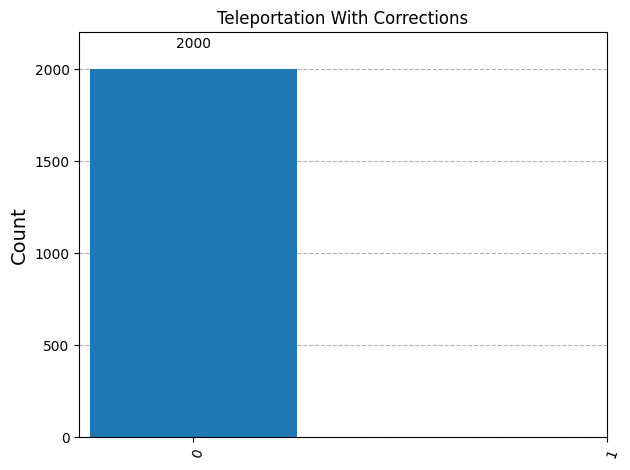


Accuracy without corrections: 49.95 %
Receiver measurement counts: {'0': 999, '1': 1001}


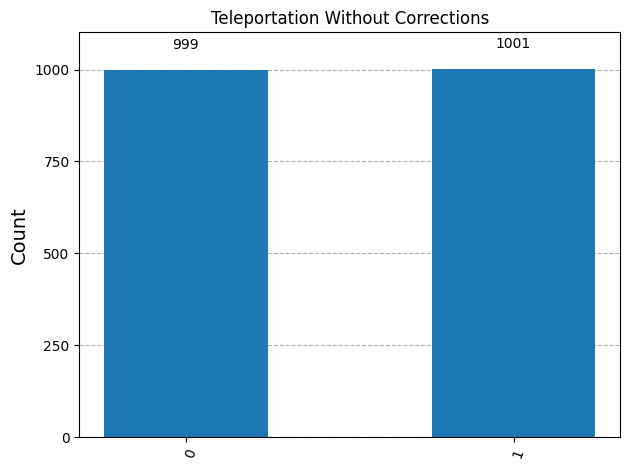


Gold: Interpretation
With corrections, accuracy should approach 100%.
Without corrections, accuracy should approach 50%.
Entanglement alone cannot transmit usable information faster than light.


In [30]:

from IPython.display import display

a = 1.0

def teleport(with_correction=True):
    q = QuantumRegister(3)
    c0 = ClassicalRegister(1, "c0")
    c1 = ClassicalRegister(1, "c1")
    co = ClassicalRegister(1, "co")

    qc = QuantumCircuit(q, c0, c1, co)

    # Prepare the input state
    qc.ry(a, q[0])

    # Create an entangled pair
    qc.h(q[1])
    qc.cx(q[1], q[2])

    # Bell measurement
    qc.cx(q[0], q[1])
    qc.h(q[0])
    qc.measure(q[0], c0)
    qc.measure(q[1], c1)

    # Classical corrections
    if with_correction:
        with qc.if_test((c1, 1)):
            qc.x(q[2])

        with qc.if_test((c0, 1)):
            qc.z(q[2])

    # Check whether the original state was recovered
    qc.ry(-a, q[2])
    qc.measure(q[2], co)

    return qc


def receiver_counts(counts):
    result = {"0": 0, "1": 0}

    for key, value in counts.items():
        bit = key.split()[0] if " " in key else key
        result[bit[0]] += value

    return result


def receiver_accuracy(counts):
    result = receiver_counts(counts)
    total = sum(result.values())
    return round(100 * result["0"] / total, 2)


# BRONZE: Teleportation with corrections
qc_corrected = teleport(True)

print("Bronze: Teleportation circuit with corrections")
display(qc_corrected.draw("text"))

counts_corrected = run(qc_corrected, shots=2000)
corrected_results = receiver_counts(counts_corrected)

print("Accuracy with corrections:", receiver_accuracy(counts_corrected), "%")
print("Receiver measurement counts:", corrected_results)
display(plot_histogram(corrected_results, title="Teleportation With Corrections"))


# SILVER: Teleportation without corrections
qc_uncorrected = teleport(False)

counts_uncorrected = run(qc_uncorrected, shots=2000)
uncorrected_results = receiver_counts(counts_uncorrected)

print("\nAccuracy without corrections:", receiver_accuracy(counts_uncorrected), "%")
print("Receiver measurement counts:", uncorrected_results)
display(plot_histogram(uncorrected_results, title="Teleportation Without Corrections"))


# GOLD: Interpretation
print("\nGold: Interpretation")
print("With corrections, accuracy should approach 100%.")
print("Without corrections, accuracy should approach 50%.")
print("Entanglement alone cannot transmit usable information faster than light.")


Quantum teleportation recovers the intended state when classical measurement results are used for corrections, demonstrating that entanglement alone cannot transmit usable information faster than light.